# Used Car Price Prediction (Belarus)
**Student:** Adilkhan Dzhanteliev EEAIR24
**Link:** https://www.kaggle.com/datasets/slavapasedko/belarus-used-cars-prices

## Part 1: Problem and cleaning
**What do we predict:** Price of a used car in USD (priceUSD)
**Number or class:** A number, so this is a **regression** task
**Score:** R^2 (how much of the price variation the model explains) and RMSE (average error)

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
url = 'https://raw.githubusercontent.com/AdilkhanEEAIR/machines_predict_ml/main/data/cars.csv'
df = pd.read_csv(url)
print(df.shape)
df.head()

(56244, 12)


,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56244 entries, 0 to 56243
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make                 56244 non-null  object 
 1   model                56244 non-null  object 
 2   priceUSD             56244 non-null  int64  
 3   year                 56244 non-null  int64  
 4   condition            56244 non-null  object 
 5   mileage(kilometers)  56244 non-null  float64
 6   fuel_type            56244 non-null  object 
 7   volume(cm3)          56197 non-null  float64
 8   color                56244 non-null  object 
 9   transmission         56244 non-null  object 
 10  drive_unit           54339 non-null  object 
 11  segment              50953 non-null  object 
dtypes: float64(2), int64(2), object(8)
memory usage: 5.1+ MB


In [28]:
df = df.rename(columns={"mileage(kilometers)": "mileage", "volume(cm3)": "volume"})
df.isna().sum()

make               0
model              0
priceUSD           0
year               0
condition          0
mileage            0
fuel_type          0
volume            47
color              0
transmission       0
drive_unit      1905
segment         5291
dtype: int64

In [29]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicates: 87


In [30]:
print(df["condition"].value_counts())
print(df.groupby("condition")["priceUSD"].mean())
df = df[df["condition"] == "with mileage"]
df = df.drop("condition", axis=1)

condition
with mileage    55191
with damage       512
for parts         454
Name: count, dtype: int64
condition
for parts        596.405286
with damage     2721.089844
with mileage    7517.210197
Name: priceUSD, dtype: float64


In [31]:
df.describe()

,priceUSD,year,mileage,volume
count,55191.000000,55191.000000,5.519100e+04,55144.000000
mean,7517.210197,2003.586092,2.430682e+05,2108.672077
std,8347.859626,8.063917,3.103947e+05,959.693755
min,100.000000,1933.000000,0.000000e+00,500.000000
25%,2500.000000,1998.000000,1.370000e+05,1600.000000
50%,5500.000000,2004.000000,2.274000e+05,2000.000000
75%,9950.000000,2010.000000,3.090000e+05,2300.000000
max,235235.000000,2019.000000,9.999999e+06,20000.000000


In [32]:
# чистка год
df = df[df["year"] >= 1980]
print(df.shape)

(54952, 11)


In [33]:
# пробег чистка
df = df[df["mileage"] > 0]
df = df[df["mileage"] <= 1000000]
print(df.shape)

(54444, 11)


In [34]:
# обьем двигателя чистка
df = df[(df["volume"] >= 600) & (df["volume"] <= 7000) | (df["volume"].isna())]
print(df.shape)

(54345, 11)


In [35]:
# чистка цены
low = df["priceUSD"].quantile(0.01)
high = df["priceUSD"].quantile(0.99)
print(low, high)

400.0 39900.0


In [36]:
df = df[df["priceUSD"] >= low]
df = df[df["priceUSD"] <= high]
print(df.shape)

(53325, 11)


**Cleaning choices:**
- **Missing values:** `segment`, `drive_unit` and `volume` have empty values. I'll keep these rows and fill them in pipeline in 3rd part, because deleting them would lose many cars
- **Wrong types:** all types are correct, I only renamed `mileage(kilometers)` and `volume(cm3)`,  because brackets are not comfortable in code for me
- **Duplicates:** I've removed 87 copies, the same car is not counted twice
- **Condition:** cars "for parts" and "with damage" are very  cheaper. They are in different market and I kept only normal used cars and dropped column
- **Extreme values:** I have removed cars older than 1980 (rare cars), mileage 0 or more than 1000000 km (mistakes), engine volume outside 600–7000 (not real), and the lowest and highest 1% of prices

After cleaning: 53,325 rows.

## Part 2: Charts and Graphs

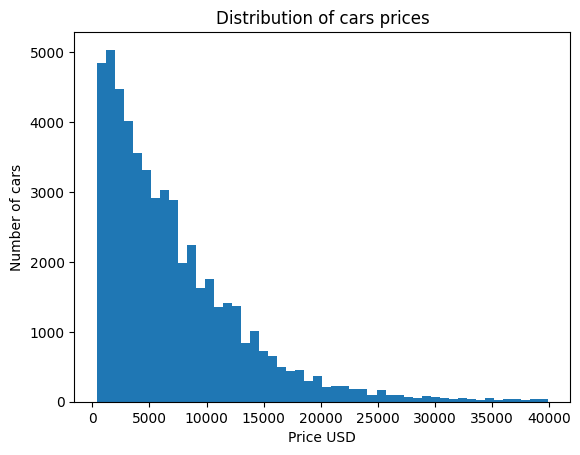

In [37]:
plt.hist(df['priceUSD'], bins=50)
plt.title('Distribution of cars prices')
plt.xlabel('Price USD')
plt.ylabel('Number of cars')
plt.show()

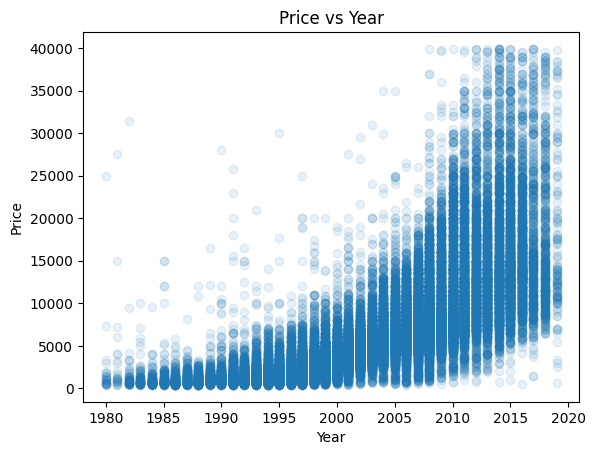

In [38]:
plt.scatter(df['year'], df['priceUSD'], alpha=0.1)
plt.title("Price vs Year")
plt.xlabel('Year')
plt.ylabel('Price')
plt.show()

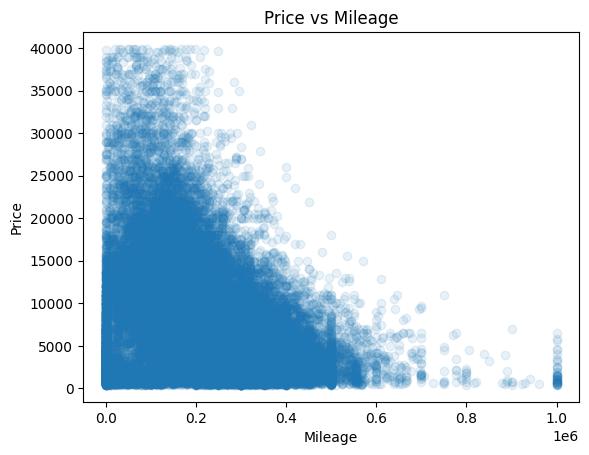

In [39]:
plt.scatter(df['mileage'], df['priceUSD'], alpha=0.1)
plt.title('Price vs Mileage')
plt.xlabel('Mileage')
plt.ylabel('Price')
plt.show()

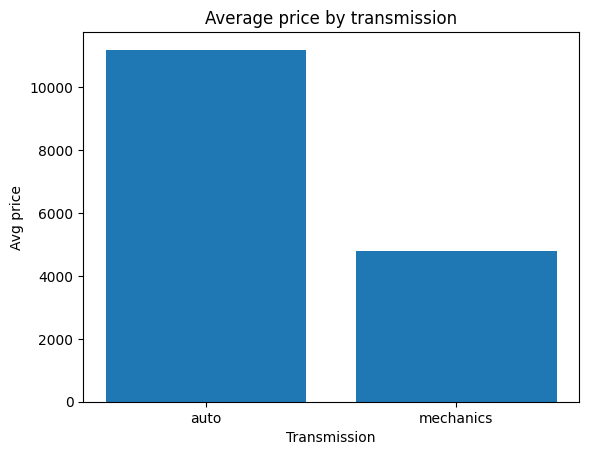

In [40]:
avg = df.groupby('transmission')['priceUSD'].mean()
plt.bar(avg.index, avg.values)
plt.title('Average price by transmission')
plt.xlabel('Transmission')
plt.ylabel('Avg price')
plt.show()

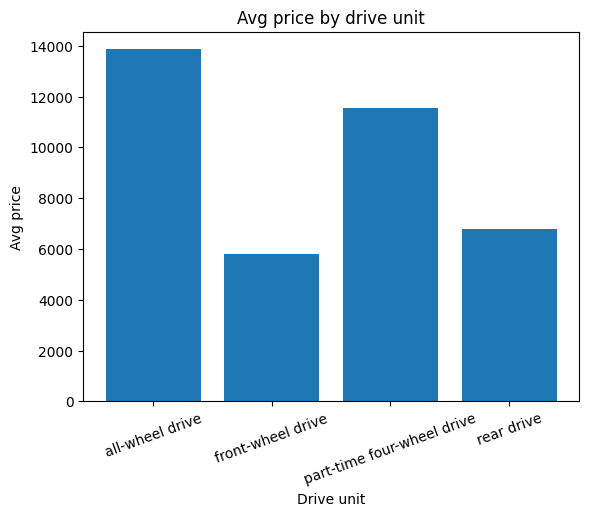

In [41]:
avg = df.groupby('drive_unit')['priceUSD'].mean()
plt.bar(avg.index, avg.values)
plt.title('Avg price by drive unit')
plt.xlabel('Drive unit')
plt.ylabel('Avg price')
plt.xticks(rotation=20)
plt.show()

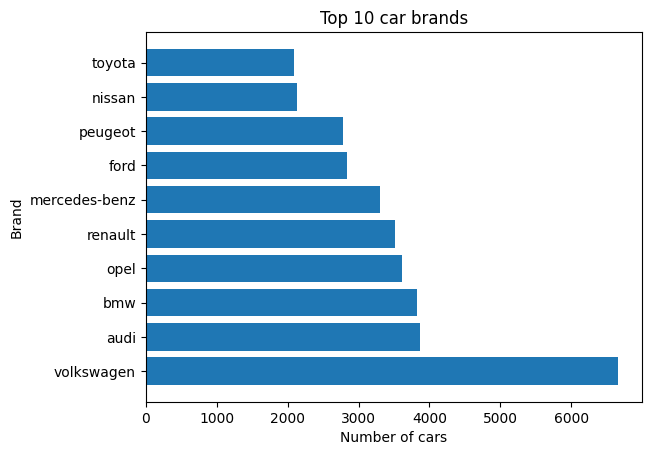

In [42]:
top = df['make'].value_counts().head(10)
plt.barh(top.index, top.values)
plt.title('Top 10 car brands')
plt.xlabel('Number of cars')
plt.ylabel('Brand')
plt.show()

**What I learned:**
1. **Price histogram:** most cars are cheap under 10k $. There are only a few expensive cars and graph has a long tail to the right
2. **Price vs year:** newer cars cost more, the points go up from left to right
3. **Price vs mileage:** cars with more mileage are cheaper, but the points are very spread out, so mileage matters less than year
4. **Transmission:** automatic cars are on average about 2 times more expensive than manual cars
5. **Drive unit:** all-wheel drive cars are the most expensive, front-wheel drive cars are the cheapest
6. **Brands:** Volkswagen, Audi and BMW are the most common cars in the dataset